# Import Modules

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
from sklearn.model_selection import train_test_split, GridSearchCV, RandomizedSearchCV, StratifiedKFold
from sklearn.metrics import accuracy_score, classification_report, roc_auc_score
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import GridSearchCV
import joblib

In [3]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from xgboost import XGBClassifier

# Reading the Dataset

In [4]:
df = pd.read_csv('./data/Telco-Customer-Churn.csv')
df = df.drop(columns=['customerID'], axis=1)

In [5]:
df.sample(7)

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
6289,Male,0,No,No,67,Yes,Yes,Fiber optic,Yes,Yes,Yes,Yes,Yes,Yes,Two year,No,Credit card (automatic),116.20,7752.3,Yes
3633,Female,1,No,No,1,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,71.25,71.25,No
3782,Female,0,No,Yes,12,Yes,Yes,Fiber optic,No,No,No,No,Yes,No,Month-to-month,Yes,Electronic check,84.05,966.55,No
4331,Male,0,No,No,71,Yes,Yes,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Bank transfer (automatic),25.55,1898.1,No
3502,Male,0,No,No,44,No,No phone service,DSL,Yes,No,Yes,No,Yes,Yes,One year,Yes,Electronic check,54.00,2440.25,No
4945,Male,0,Yes,Yes,20,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.05,400,No
4491,Male,0,No,No,1,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Month-to-month,Yes,Credit card (automatic),19.75,19.75,No


# Exploring the Dataset

## How big is the data

In [6]:
rows = df.shape[0]
cols = df.shape[1]
print(f"Data has {rows} rows, {cols} columns.")

Data has 7043 rows, 20 columns.


## How does the data look like

In [7]:
df.sample(7)

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
3571,Female,0,No,No,35,Yes,No,DSL,No,No,Yes,No,No,Yes,Month-to-month,Yes,Electronic check,62.10,2096.1,No
2954,Female,0,No,No,7,Yes,Yes,Fiber optic,No,No,No,No,No,No,Month-to-month,No,Mailed check,75.45,480.75,Yes
2770,Male,0,Yes,Yes,17,Yes,Yes,Fiber optic,No,No,No,No,Yes,Yes,Month-to-month,Yes,Electronic check,92.55,1515.1,Yes
367,Female,0,No,No,1,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Month-to-month,No,Mailed check,19.15,19.15,No
4441,Male,0,Yes,No,42,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Electronic check,20.25,835.5,No
5653,Female,0,No,No,7,Yes,No,Fiber optic,No,No,No,No,Yes,No,Month-to-month,Yes,Electronic check,79.00,522.95,Yes
1074,Male,0,No,No,1,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Month-to-month,No,Mailed check,21.10,21.1,No


## What is the data type of cols

In [8]:
df.dtypes

gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges         object
Churn                object
dtype: object

## Are there any missing values

In [9]:
df.isnull().sum()

gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

## How does the data look mathematically

In [10]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


## Information about data

In [11]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 20 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   gender            7043 non-null   object 
 1   SeniorCitizen     7043 non-null   int64  
 2   Partner           7043 non-null   object 
 3   Dependents        7043 non-null   object 
 4   tenure            7043 non-null   int64  
 5   PhoneService      7043 non-null   object 
 6   MultipleLines     7043 non-null   object 
 7   InternetService   7043 non-null   object 
 8   OnlineSecurity    7043 non-null   object 
 9   OnlineBackup      7043 non-null   object 
 10  DeviceProtection  7043 non-null   object 
 11  TechSupport       7043 non-null   object 
 12  StreamingTV       7043 non-null   object 
 13  StreamingMovies   7043 non-null   object 
 14  Contract          7043 non-null   object 
 15  PaperlessBilling  7043 non-null   object 
 16  PaymentMethod     7043 non-null   object 


## Are there duplicate values

In [12]:
duplicate_count = df.duplicated().sum()
duplicates = df[df.duplicated()]
print(f"There are {duplicate_count} duplicate rows in the data.")
duplicates

There are 22 duplicate rows in the data.


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
964,Male,0,No,No,1,Yes,No,DSL,No,No,No,No,No,No,Month-to-month,Yes,Mailed check,45.70,45.7,Yes
1338,Male,0,No,No,1,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Month-to-month,No,Mailed check,20.15,20.15,Yes
1491,Female,0,No,No,1,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Month-to-month,No,Mailed check,19.55,19.55,No
1739,Male,0,No,No,1,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,69.90,69.9,Yes
1932,Male,0,No,No,1,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Month-to-month,No,Mailed check,20.20,20.2,No
2713,Male,0,No,No,1,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Month-to-month,Yes,Mailed check,20.45,20.45,No
2892,Male,0,No,No,1,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Month-to-month,No,Mailed check,20.45,20.45,No
3301,Female,1,No,No,1,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,69.60,69.6,Yes
3754,Male,0,No,No,1,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Month-to-month,No,Mailed check,20.05,20.05,No
4098,Male,0,No,No,1,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Month-to-month,Yes,Mailed check,20.20,20.2,Yes


# How is the correlation between cols

In [13]:
df.corr(numeric_only=True)

,SeniorCitizen,tenure,MonthlyCharges
SeniorCitizen,1.000000,0.016567,0.220173
tenure,0.016567,1.000000,0.247900
MonthlyCharges,0.220173,0.247900,1.000000


# Data Manipulation

## tenure

In [14]:
df.drop(labels=df[df['tenure'] == 0].index, axis=0, inplace=True)
df[df['tenure'] == 0].shape

(0, 20)

In [15]:
df.isnull().sum()

gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

## SeniorCitizen

In [16]:
df["SeniorCitizen"] = df["SeniorCitizen"].map({0: "No", 1: "Yes"})

In [17]:
df.sample(5)

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
2210,Female,No,No,No,69,Yes,Yes,Fiber optic,No,No,Yes,Yes,Yes,Yes,Two year,No,Electronic check,104.00,7028.5,No
2236,Male,Yes,No,No,5,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Mailed check,71.45,371.6,No
5934,Female,Yes,Yes,No,26,Yes,Yes,Fiber optic,No,Yes,Yes,No,No,Yes,Month-to-month,Yes,Electronic check,93.85,2381.55,Yes
3463,Male,No,No,No,37,Yes,Yes,Fiber optic,Yes,No,No,No,Yes,No,Month-to-month,Yes,Electronic check,91.15,3369.25,No
6588,Female,No,Yes,Yes,23,Yes,Yes,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,23.85,625.65,No


## TotalCharges

In [18]:
df["TotalCharges"] = df["TotalCharges"].astype(float)

In [19]:
df.describe()

,tenure,MonthlyCharges,TotalCharges
count,7032.000000,7032.000000,7032.000000
mean,32.421786,64.798208,2283.300441
std,24.545260,30.085974,2266.771362
min,1.000000,18.250000,18.800000
25%,9.000000,35.587500,401.450000
50%,29.000000,70.350000,1397.475000
75%,55.000000,89.862500,3794.737500
max,72.000000,118.750000,8684.800000


# Data Visualization

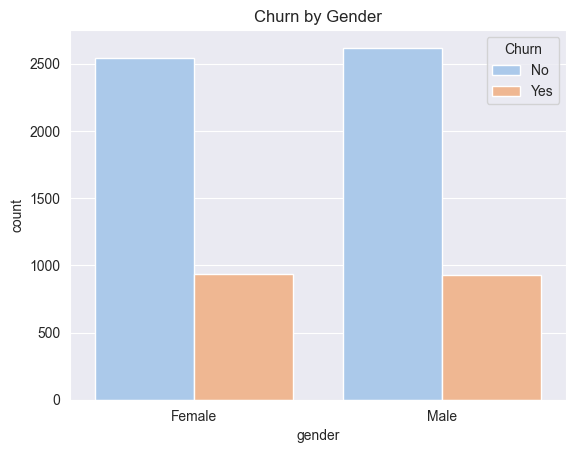

In [20]:
sns.countplot(x='gender', hue='Churn', data=df, palette='pastel')
plt.title('Churn by Gender')
plt.show()


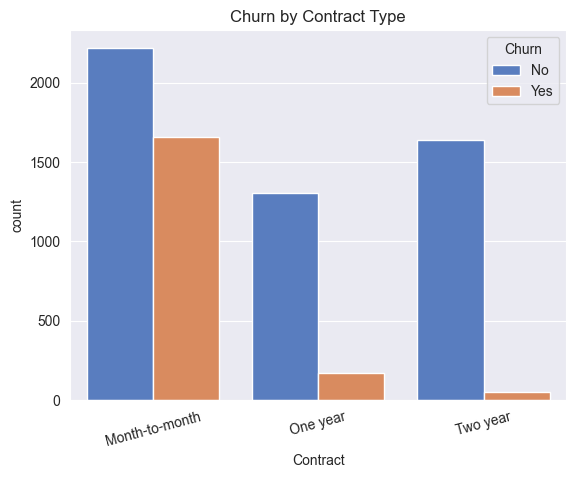

In [21]:
sns.countplot(x='Contract', hue='Churn', data=df, palette='muted')
plt.title('Churn by Contract Type')
plt.xticks(rotation=15)
plt.show()


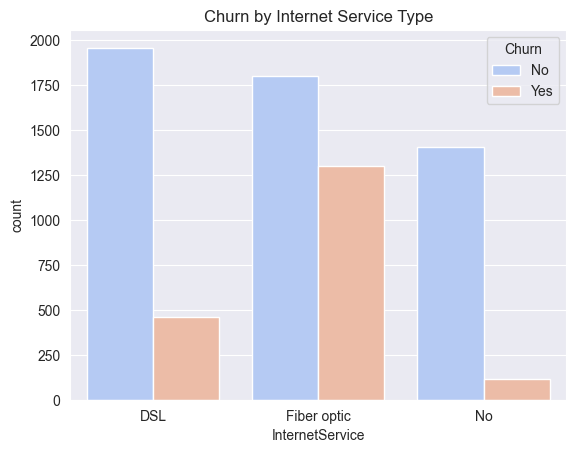

In [22]:
sns.countplot(x='InternetService', hue='Churn', data=df, palette='coolwarm')
plt.title('Churn by Internet Service Type')
plt.show()


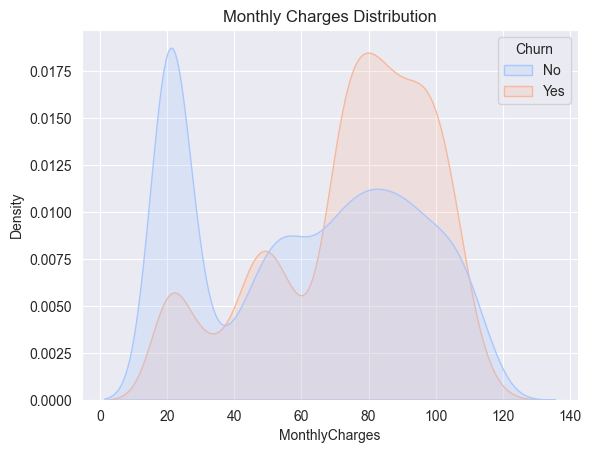

In [23]:
sns.kdeplot(data=df, x='MonthlyCharges', hue='Churn', fill=True, common_norm=False, palette='coolwarm')
plt.title('Monthly Charges Distribution')
plt.show()


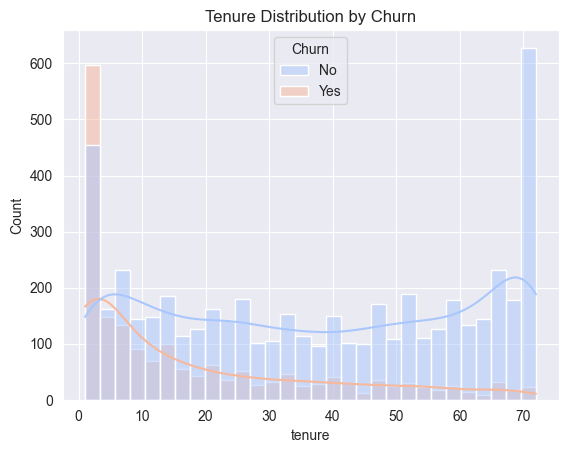

In [24]:
sns.histplot(data=df, x='tenure', hue='Churn', bins=30, kde=True, palette='coolwarm')
plt.title('Tenure Distribution by Churn')
plt.show()


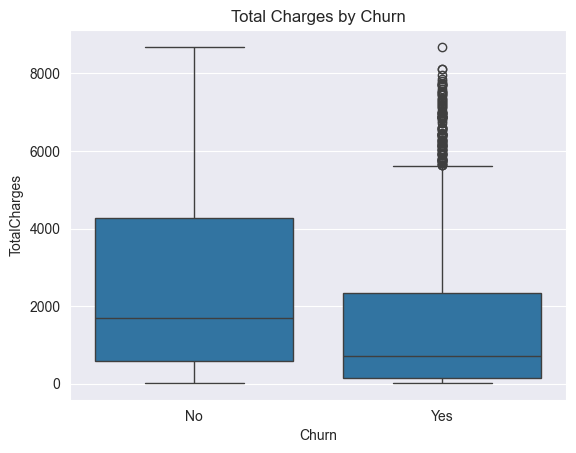

In [25]:
sns.boxplot(x='Churn', y='TotalCharges', data=df)
plt.title('Total Charges by Churn')
plt.show()


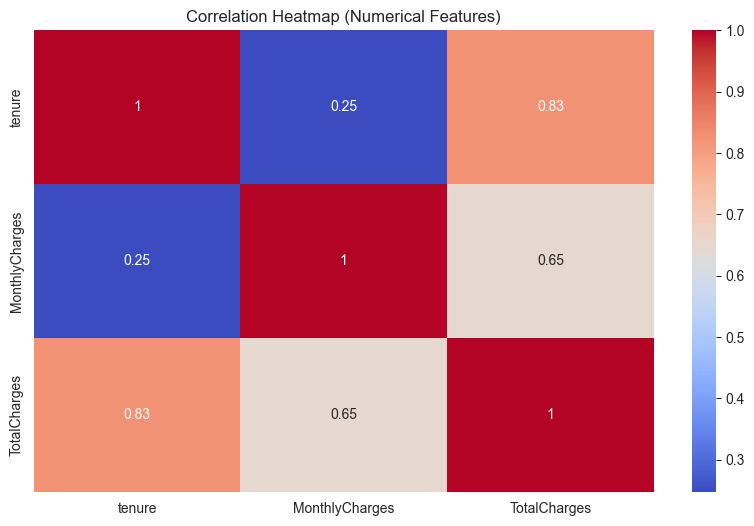

In [26]:
plt.figure(figsize=(10, 6))
corr = df[['tenure', 'MonthlyCharges', 'TotalCharges']].corr()
sns.heatmap(corr, annot=True, cmap='coolwarm')
plt.title('Correlation Heatmap (Numerical Features)')
plt.show()


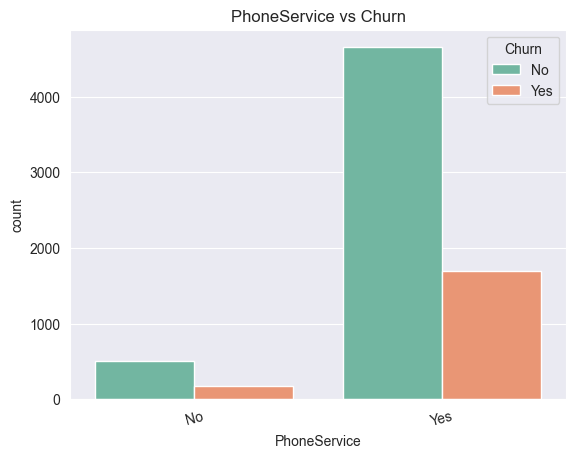

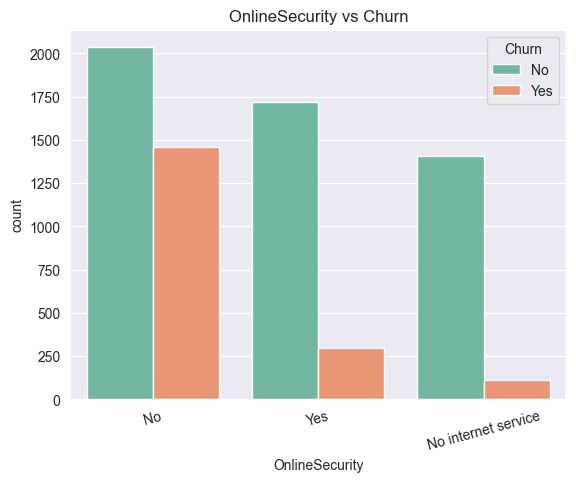

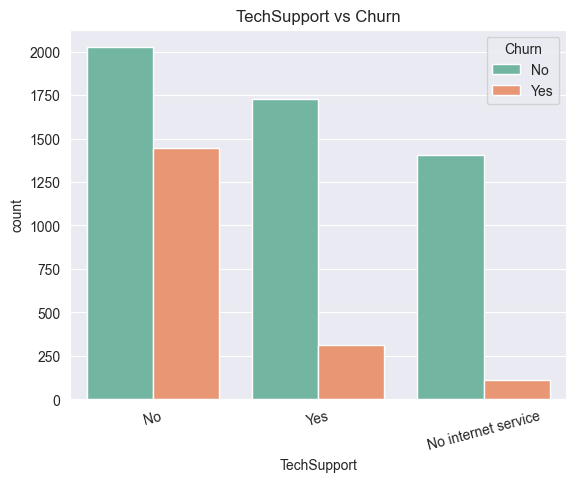

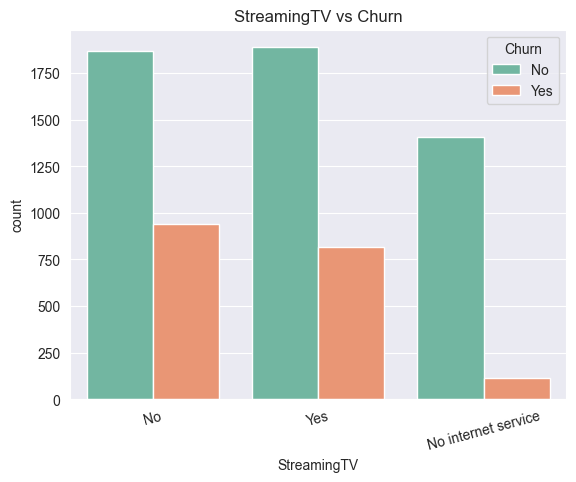

In [27]:
features = ['PhoneService', 'OnlineSecurity', 'TechSupport', 'StreamingTV']
for feature in features:
    sns.countplot(x=feature, hue='Churn', data=df, palette='Set2')
    plt.title(f'{feature} vs Churn')
    plt.xticks(rotation=15)
    plt.show()


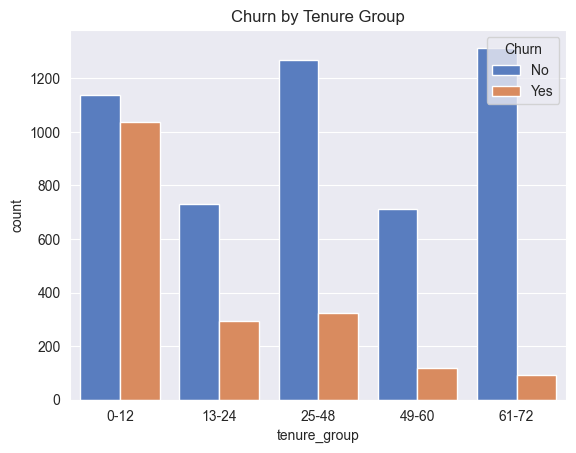

In [28]:
df['tenure_group'] = pd.cut(df['tenure'], bins=[0, 12, 24, 48, 60, 72],
                            labels=['0-12', '13-24', '25-48', '49-60', '61-72'])

sns.countplot(x='tenure_group', hue='Churn', data=df, palette='muted')
plt.title('Churn by Tenure Group')
plt.show()


# Data Preprocessing

In [29]:
df['Churn'] = df['Churn'].map({'Yes': 1, 'No': 0})

In [30]:
X = df.drop(columns=['Churn'], axis=1)
y = df['Churn']

## Binary Columns

In [31]:
binary_cols = [col for col in X.columns if X[col].nunique() == 2 and X[col].dtype == 'object']
binary_cols

['gender',
 'SeniorCitizen',
 'Partner',
 'Dependents',
 'PhoneService',
 'PaperlessBilling']

In [32]:
for col in binary_cols:
    X[col] = X[col].map({'Yes': 1, 'No': 0, 'Male': 1, 'Female': 0})

In [33]:
X[binary_cols].sample(7)

,gender,SeniorCitizen,Partner,Dependents,PhoneService,PaperlessBilling
5089,1,0,1,1,1,1
128,1,0,0,0,1,0
2252,0,0,1,1,1,0
4701,1,1,0,0,1,1
68,0,0,1,1,1,0
1269,1,0,1,1,1,0
5895,0,0,1,1,1,1


In [34]:
multi_categories_cols = [
    'MultipleLines',
    'OnlineSecurity',
    'OnlineBackup',
    'DeviceProtection',
    'TechSupport',
    'StreamingTV',
    'StreamingMovies'
]

In [35]:
X[multi_categories_cols] = X[multi_categories_cols].replace({
    'Yes': 1,
    'No': 0,
    'No internet service': 0,
    'No phone service': 0
})

C:\Users\User\AppData\Local\Temp\ipykernel_11976\3502903722.py:1: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  X[multi_categories_cols] = X[multi_categories_cols].replace({


In [36]:
binary_cols += multi_categories_cols

In [37]:
X[binary_cols]

,gender,SeniorCitizen,Partner,Dependents,PhoneService,PaperlessBilling,MultipleLines,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies
0,0,0,1,0,0,1,0,0,1,0,0,0,0
1,1,0,0,0,1,0,0,1,0,1,0,0,0
2,1,0,0,0,1,1,0,1,1,0,0,0,0
3,1,0,0,0,0,0,0,1,0,1,1,0,0
4,0,0,0,0,1,1,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
7038,1,0,1,1,1,1,1,1,0,1,1,1,1
7039,0,0,1,1,1,1,1,0,1,1,0,1,1
7040,0,0,1,1,0,1,0,1,0,0,0,0,0
7041,1,1,1,0,1,1,1,0,0,0,0,0,0


In [38]:
X.dtypes

gender                 int64
SeniorCitizen          int64
Partner                int64
Dependents             int64
tenure                 int64
PhoneService           int64
MultipleLines          int64
InternetService       object
OnlineSecurity         int64
OnlineBackup           int64
DeviceProtection       int64
TechSupport            int64
StreamingTV            int64
StreamingMovies        int64
Contract              object
PaperlessBilling       int64
PaymentMethod         object
MonthlyCharges       float64
TotalCharges         float64
tenure_group        category
dtype: object

## Numerical Columns

In [39]:
numerical_cols = ['MonthlyCharges', 'TotalCharges', 'tenure']

## Categorical Columns

In [40]:
categorical_cols = X.select_dtypes(include=['object', 'category']).columns.tolist()
categorical_cols

['InternetService', 'Contract', 'PaymentMethod', 'tenure_group']

## Pipeline

In [41]:
num_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

In [42]:
cat_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

In [43]:
transformer = ColumnTransformer(transformers=[
    ('num', num_pipeline, numerical_cols),
    ('cat', cat_pipeline, categorical_cols),
], remainder='passthrough')

## Train-Test Split

In [44]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# Machine Learning Model

In [45]:
models_and_params = {
    'LogisticRegression': {
        'model': LogisticRegression(max_iter=1000),
        'params': {
            'model__C': [0.01, 0.1, 1, 10],
            'model__solver': ['lbfgs', 'liblinear']
        }
    },
    'RandomForest': {
        'model': RandomForestClassifier(random_state=42),
        'params': {
            'model__n_estimators': [100, 200],
            'model__max_depth': [10, 20, None],
            'model__min_samples_split': [2, 5],
            'model__min_samples_leaf': [1, 2]
        }
    },
    'SVM': {
        'model': SVC(),
        'params': {
            'model__C': [0.1, 1, 10],
            'model__kernel': ['linear', 'rbf']
        }
    },
    'KNN': {
        'model': KNeighborsClassifier(),
        'params': {
            'model__n_neighbors': [3, 5, 7, 9],
            'model__weights': ['uniform', 'distance']
        }
    },
    'XGBoost': {
        'model': XGBClassifier(eval_metric='logloss'),
        'params': {
            'model__n_estimators': [100, 200],
            'model__max_depth': [3, 6, 10],
            'model__learning_rate': [0.01, 0.1, 0.2]
        }
    }
}

In [46]:
best_models = {}
best_model_name = None
best_model_pipeline = None
best_model_score = 0.0

for name, config in models_and_params.items():
    pipe = Pipeline([
        ('preprocessor', transformer),
        ('model', config['model'])
    ])

    print(f"\nModel: {name}")
    grid = GridSearchCV(pipe, config['params'], cv=5, scoring='accuracy', n_jobs=-1)
    grid.fit(X_train, y_train)

    y_pred = grid.predict(X_test)
    acc = accuracy_score(y_test, y_pred)

    print(f"Best Params for {name}: {grid.best_params_}")
    print(f"Accuracy: {acc:.4f}")
    print(classification_report(y_test, y_pred))

    best_models[name] = grid.best_estimator_

    if acc > best_model_score:
        best_model_score = acc
        best_model_name = name
        best_model_pipeline = grid.best_estimator_



Model: LogisticRegression
Best Params for LogisticRegression: {'model__C': 0.1, 'model__solver': 'liblinear'}
Accuracy: 0.7943
              precision    recall  f1-score   support

           0       0.83      0.91      0.87      1549
           1       0.65      0.48      0.56       561

    accuracy                           0.79      2110
   macro avg       0.74      0.70      0.71      2110
weighted avg       0.78      0.79      0.78      2110


Model: RandomForest
Best Params for RandomForest: {'model__max_depth': 10, 'model__min_samples_leaf': 1, 'model__min_samples_split': 2, 'model__n_estimators': 200}
Accuracy: 0.7953
              precision    recall  f1-score   support

           0       0.83      0.90      0.87      1549
           1       0.65      0.50      0.57       561

    accuracy                           0.80      2110
   macro avg       0.74      0.70      0.72      2110
weighted avg       0.78      0.80      0.79      2110


Model: SVM
Best Params for SVM: {'m

In [47]:
joblib.dump(best_model_pipeline, f"{best_model_name}_model.pkl")
print(f"\nBest model saved as '{best_model_name}_model.pkl' with accuracy: {best_model_score:.4f}")


Best model saved as 'XGBoost_model.pkl' with accuracy: 0.8000
